# Student Pass/Fail Prediction — Beginner Google Colab Notebook

## Project goal
Train a simple Machine Learning model to predict whether a student will **Pass** or **Fail**.

### Features (inputs)
- `Study_Hours`: hours studied per day
- `Attendance`: percentage of classes attended
- `Previous_Marks`: marks from a previous test

### Target (what we predict)
- `Result`: Pass or Fail

This notebook follows the workflow in your slides: data quality, features and target, train/test split, model fitting, validation and cross-validation, evaluation, random seed, reproducibility, data leakage, and correlation versus causation.

**Important:** The dataset is artificial and made for teaching practice. It is not real student data.

## 1. Import libraries
Each code line below has a comment explaining its purpose.

In [ ]:
import pandas as pd

import numpy as np

import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split

from sklearn.model_selection import cross_val_score

from sklearn.pipeline import Pipeline

from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression

from sklearn.metrics import accuracy_score

from sklearn.metrics import confusion_matrix

from sklearn.metrics import classification_report

from sklearn.metrics import ConfusionMatrixDisplay

np.random.seed(42)

## 2. Create a sample student dataset
We create 120 artificial student records. The Pass/Fail labels are generated from a simple made-up rule with some randomness.

In [ ]:
number_of_students = 120

study_hours = np.random.uniform(0, 8, number_of_students)

attendance = np.random.uniform(40, 100, number_of_students)

previous_marks = np.random.uniform(20, 100, number_of_students)

score = (4 * study_hours + 0.25 * (attendance - 40) + 0.25 * (previous_marks - 20) + np.random.normal(0, 5, number_of_students))

result = np.where(score >= 25, "Pass", "Fail")

df = pd.DataFrame({"Study_Hours": study_hours.round(1), "Attendance": attendance.round(1), "Previous_Marks": previous_marks.round(1), "Result": result})

df.head()

,Study_Hours,Attendance,Previous_Marks,Result
0,3.0,88.4,95.2,Pass
1,7.6,93.8,96.3,Pass
2,5.9,59.1,93.2,Pass
3,4.8,46.6,49.6,Fail
4,1.2,53.7,21.2,Fail


## 3. Check data quality
Your slides explain that we should inspect records, data types, missing values, and class balance before training.

In [ ]:
print("Dataset shape:", df.shape)
# df.shape: Displays the number of rows and columns in the dataset.
# Rows represent students, and columns represent features.

df.info()
# df.info(): Displays information about the dataset, including column names,
# data types, and the number of non-missing values.

print("Missing values in each column:")

print(df.isnull().sum())
# df.isnull(): Checks every cell and returns True if a value is missing.
# .sum(): Counts the number of missing values in each column.
# print(): Displays the results.

print("Number of Pass and Fail students:")

print(df["Result"].value_counts())
# df["Result"]: Selects the Result column from the dataset.
# .value_counts(): Counts how many times each unique value appears,


df.describe()
# df.describe(): Generates statistical information about numerical columns,
# including count, mean, standard deviation, minimum, maximum,
# and quartiles (25%, 50%, and 75%).


Dataset shape: (120, 4)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 120 entries, 0 to 119
Data columns (total 4 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Study_Hours     120 non-null    float64
 1   Attendance      120 non-null    float64
 2   Previous_Marks  120 non-null    float64
 3   Result          120 non-null    object 
dtypes: float64(3), object(1)
memory usage: 3.9+ KB
Missing values in each column:
Study_Hours       0
Attendance        0
Previous_Marks    0
Result            0
dtype: int64
Number of Pass and Fail students:
Result
Pass    84
Fail    36
Name: count, dtype: int64


,Study_Hours,Attendance,Previous_Marks
count,120.000000,120.000000,120.000000
mean,3.821667,69.006667,60.780833
std,2.383775,17.243222,23.352438
min,0.000000,40.300000,21.200000
25%,1.600000,54.375000,42.775000
50%,3.900000,70.200000,62.900000
75%,6.025000,82.325000,79.075000
max,7.900000,99.100000,99.200000


## 4. Visualize the data
This graph helps us see how study hours and previous marks are associated with the Pass/Fail labels. A relationship in the graph does not prove causation.

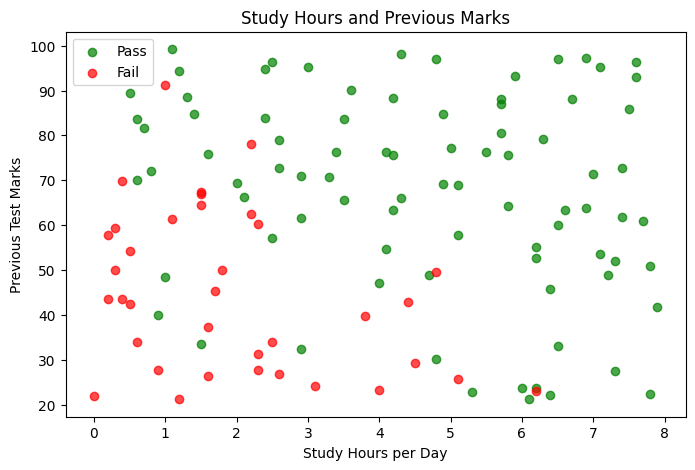

In [ ]:
plt.figure(figsize=(8, 5))

pass_students = df[df["Result"] == "Pass"]

plt.scatter(pass_students["Study_Hours"], pass_students["Previous_Marks"], color="green", label="Pass", alpha=0.7)

fail_students = df[df["Result"] == "Fail"]

plt.scatter(fail_students["Study_Hours"], fail_students["Previous_Marks"], color="red", label="Fail", alpha=0.7)

plt.title("Study Hours and Previous Marks")

plt.xlabel("Study Hours per Day")

plt.ylabel("Previous Test Marks")

plt.legend()

plt.show()

## 5. Separate features (X) and target (y)

- **X:** the input information the model uses.
- **y:** the answer the model learns to predict.

We do not include final-exam marks because they would not be available before the final exam. Using them could cause data leakage.

In [ ]:
X = df[["Study_Hours", "Attendance", "Previous_Marks"]]

y = df["Result"]

display(X.head())

display(y.head())

,Study_Hours,Attendance,Previous_Marks
0,3.0,88.4,95.2
1,7.6,93.8,96.3
2,5.9,59.1,93.2
3,4.8,46.6,49.6
4,1.2,53.7,21.2


,Result
0,Pass
1,Pass
2,Pass
3,Fail
4,Fail


## 6. Split data into training and testing sets

- Training data teaches the model.
- Test data is kept separate for final evaluation.
- `test_size=0.20` means 20% of records are held out for testing.
- `random_state=42` makes the split repeatable.
- `stratify=y` helps keep similar Pass/Fail proportions in both sets.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(

    X,

    y,

    test_size=0.20,

    random_state=42,

    stratify=y
)

print("Training records:", len(X_train))

print("Testing records:", len(X_test))

Training records: 96
Testing records: 24


## 7. Build and train the model

We use **Logistic Regression**, a simple classification algorithm.

The pipeline has two steps:
1. Scale the numeric features.
2. Train Logistic Regression to classify Pass and Fail.

A pipeline keeps preprocessing and model fitting together. This is useful when we perform cross-validation.

In [ ]:
model = Pipeline([

    ("scaler", StandardScaler()),

    ("classifier", LogisticRegression(max_iter=1000))
])

model.fit(X_train, y_train)

print("Model training completed.")

Model training completed.


## 8.  Cross-validation
Cross-validation divides the training data into five parts. Each part takes a turn as validation data while the other four parts train the model. The test set is not used here.

In [ ]:
cv_scores = cross_val_score(

    model,

    X_train,

    y_train,

    cv=5,

    scoring="accuracy"
)

print("Accuracy in each fold:", cv_scores)

print("Average cross-validation accuracy:", round(cv_scores.mean(), 3))

Accuracy in each fold: [0.85       0.78947368 0.94736842 0.94736842 0.89473684]
Average cross-validation accuracy: 0.886


## 9. Evaluate the model on the test set
Now we use the held-back test data once to estimate how well the trained model predicts unseen examples.

Test Accuracy: 95.83 %


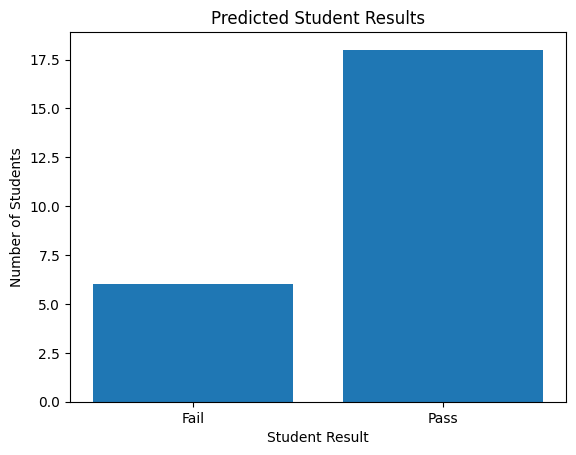

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import accuracy_score

# Step 1: Make predictions using testing data
y_pred = model.predict(X_test)

# Step 2: Calculate test accuracy
test_accuracy = accuracy_score(y_test, y_pred)

# Step 3: Display test accuracy as a percentage
print("Test Accuracy:", round(test_accuracy * 100, 2), "%")

# Step 4: Count the predicted Pass and Fail students
prediction_counts = pd.Series(y_pred).value_counts()

# Step 5: Get the number of Pass and Fail predictions
fail_count = prediction_counts.get("Fail", 0)
pass_count = prediction_counts.get("Pass", 0)

# Step 6: Create a bar graph
plt.bar(["Fail", "Pass"], [fail_count, pass_count])

# Step 7: Add graph title and labels
plt.title("Predicted Student Results")
plt.xlabel("Student Result")
plt.ylabel("Number of Students")

# Step 8: Display the graph
plt.show()

## 10. Predict the result for a new student
Enter example information for a student. The model will predict Pass or Fail.

In [ ]:
new_student = pd.DataFrame({"Study_Hours": [4.5], "Attendance": [85.0], "Previous_Marks": [65.0]})

prediction = model.predict(new_student)

print("Predicted result:", prediction[0])

probabilities = model.predict_proba(new_student)

print("Class order:", model.named_steps["classifier"].classes_)

print("Predicted probabilities:", probabilities[0].round(3))

Predicted result: Pass
Class order: ['Fail' 'Pass']
Predicted probabilities: [0.038 0.962]


## 11. Learned parameters and hyperparameters
Logistic Regression learns coefficients from the training data. These coefficients are learned parameters. `max_iter=1000` is a setting chosen by us, so it is a hyperparameter.

In [ ]:
learned_coefficients = model.named_steps["classifier"].coef_[0]

coefficient_table = pd.DataFrame({"Feature": X.columns, "Learned_Coefficient": learned_coefficients})

coefficient_table

,Feature,Learned_Coefficient
0,Study_Hours,1.857858
1,Attendance,0.661225
2,Previous_Marks,1.591850


## 12. Connect the practical work to the slides

| Slide topic | Where it appears in this notebook |
|---|---|
| Data quality | Checking data types, missing values, and class counts |
| Features and target | `X` contains the inputs; `y` contains Pass/Fail |
| Feature choice | Study hours, attendance, and previous marks |
| Data leakage | Do not use final-exam marks before the exam |
| Train/test split | `train_test_split()` |
| Model fitting | `model.fit()` |
| Pipeline | Scaling followed by Logistic Regression |
| Validation and cross-validation | `cross_val_score()` with five folds |
| Evaluation | Accuracy, classification report, confusion matrix |
| Random seed and reproducibility | `random_state=42` and `np.random.seed(42)` |
| Correlation vs causation | Patterns can help prediction but do not prove cause and effect |

### Important limitations
This is a small artificial dataset created from a made-up rule. Its scores are for learning how the workflow works, not evidence that the model can reliably predict real students' results. A real project needs reliable data, checks for bias and leakage, suitable evaluation, and human oversight.

**Key message:** A model can learn patterns and make predictions, but a prediction is not guaranteed and does not prove that one feature causes the outcome.